# CropGuard AI — Deep Learning Fundamentals
## Notebook 02: Loss Functions, Backpropagation & First-Order Optimizers

**Course Alignment:** UPES Deep Learning Course Plan (CSAI3027P) — **Unit I: Backpropagation, Gradient Descent, Momentum, Nesterov, SGD & Optimizers**

> **Welcome back to CropGuard AI!**
> In Notebook 01, we studied the forward pass of neurons and how Multilayer Perceptrons (MLPs) can form non-linear decision boundaries.
> In this notebook, we answer the core question of deep learning: **How do neural networks actually learn?**
> We will derive and implement **forward propagation, loss functions, the chain rule, backpropagation, and first-order optimization algorithms** from first principles, accompanied by visual trajectory plots and Keras comparisons.
> 
> **Kernel:** `CropGuard AI (.venv)` (`Python 3.14.4` with NVIDIA GeForce RTX 5060 GPU acceleration).

---
### Table of Contents
0. [Environment & GPU Setup](#topic-0)
1. [Forward Propagation in a Computational Graph](#topic-1)
2. [Loss Functions: MSE vs. Binary Cross-Entropy](#topic-2)
3. [Gradients and the Multivariate Chain Rule](#topic-3)
4. [Backpropagation with a Concrete Numerical Example](#topic-4)
5. [Manual Weight and Bias Updates](#topic-5)
6. [Batch Gradient Descent vs. Stochastic GD (SGD) vs. Mini-Batch](#topic-6)
7. [Momentum Optimization: Overcoming Ravines and Oscillations](#topic-7)
8. [Nesterov Accelerated Gradient (NAG): Look-Ahead Braking](#topic-8)
9. [Benchmark Comparison of Optimizers on Crop Classification](#topic-9)
10. [Exercises & Viva Preparation](#topic-10)

---
<a id='topic-0'></a>
## 0. Environment Setup & Hardware Verification

Let us import our core scientific libraries (`numpy`, `matplotlib`, `tensorflow`) and confirm GPU readiness.

In [4]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(f"Python Version    : {sys.version.split()[0]}")
print(f"NumPy Version     : {np.__version__}")
print(f"TensorFlow Version: {tf.__version__}")

# Verify GPU device availability
gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs Detected     : {len(gpus)}")
for i, gpu in enumerate(gpus):
    print(f"  - GPU {i}: {gpu.name}")

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU Memory Growth : Enabled successfully")
    except RuntimeError as e:
        print(f"Notice: {e}")
else:
    print("Running in CPU mode.")

Python Version    : 3.14.4
NumPy Version     : 2.5.4
TensorFlow Version: 2.22.0-rc0
GPUs Detected     : 1
  - GPU 0: /physical_device:GPU:0
GPU Memory Growth : Enabled successfully


---
<a id='topic-1'></a>
## 1. Forward Propagation in a Computational Graph

### A. Markdown Explanation
**Forward Propagation** is the process where input features $\mathbf{x}$ are fed forward through sequential layers of neurons to produce a final prediction $\hat{y}$.

Think of a neural network as a **Directed Acyclic Computational Graph**:
1. At layer $l$, each neuron computes a linear pre-activation: $z^{[l]} = \sum w_{ij}^{[l]} a_j^{[l-1]} + b_i^{[l]}$.
2. The linear sum is passed through a non-linear activation function: $a_i^{[l]} = \sigma(z_i^{[l]})$.
3. These activations become the inputs for layer $l+1$.

To compute gradients later during backpropagation, we must **cache** all intermediate values ($z$ and $a$) computed during the forward pass.

### B. Mathematical Formula
For a 2-layer network with input $\mathbf{x} \in \mathbb{R}^2$, hidden layer with 2 neurons, and 1 output neuron:

**Layer 1 (Hidden Layer):**
$$\mathbf{z}^{[1]} = \mathbf{W}^{[1]} \mathbf{x} + \mathbf{b}^{[1]} = \begin{bmatrix} w_{11}^{[1]} & w_{12}^{[1]} \\ w_{21}^{[1]} & w_{22}^{[1]} \end{bmatrix} \begin{bmatrix} x_1 \\ x_2 \end{bmatrix} + \begin{bmatrix} b_1^{[1]} \\ b_2^{[1]} \end{bmatrix}$$
$$\mathbf{a}^{[1]} = \sigma(\mathbf{z}^{[1]}) = \begin{bmatrix} \sigma(z_1^{[1]}) \\ \sigma(z_2^{[1]}) \end{bmatrix}$$

**Layer 2 (Output Layer):**
$$z^{[2]} = \mathbf{W}^{[2]} \mathbf{a}^{[1]} + b^{[2]} = w_1^{[2]} a_1^{[1]} + w_2^{[2]} a_2^{[1]} + b^{[2]}$$
$$\hat{y} = a^{[2]} = \sigma(z^{[2]})$$

### C. Simple Practical Example
Suppose we evaluate an infected leaf sample with features:
* $x_1 = 0.5$ (lesion discoloration ratio)
* $x_2 = 1.0$ (lesion count scaled)

Let us trace every intermediate calculation by hand in Python.

In [5]:
# Define activation function
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

# 1. Define input sample
x = np.array([0.5, 1.0])

# 2. Layer 1 Parameters (2 inputs -> 2 hidden neurons)
W1 = np.array([
    [0.4, 0.6],   # weights to neuron 1
    [0.2, -0.5]   # weights to neuron 2
])
b1 = np.array([-0.1, 0.2])

# 3. Layer 2 Parameters (2 hidden neurons -> 1 output neuron)
W2 = np.array([0.7, -0.9])
b2 = 0.1

# --- FORWARD PASS ---
# Step 1: Pre-activation at Hidden Layer
z1 = np.dot(W1, x) + b1
# Step 2: Post-activation at Hidden Layer
a1 = sigmoid(z1)
# Step 3: Pre-activation at Output Layer
z2 = np.dot(W2, a1) + b2
# Step 4: Final Prediction (Output)
y_hat = sigmoid(z2)

print("=== Forward Propagation Step-by-Step ===")
print(f"Input Features (x)              : {x}")
print(f"Hidden Pre-activation (z^[1])   : {z1}  [z1_1={z1[0]:.4f}, z1_2={z1[1]:.4f}]")
print(f"Hidden Activations (a^[1])      : {a1}  [a1_1={a1[0]:.4f}, a1_2={a1[1]:.4f}]")
print(f"Output Pre-activation (z^[2])   : {z2:.4f}")
print(f"Final Prediction (y_hat)        : {y_hat:.4f} ({y_hat*100:.2f}% probability of disease)")

=== Forward Propagation Step-by-Step ===
Input Features (x)              : [0.5 1. ]
Hidden Pre-activation (z^[1])   : [ 0.7 -0.2]  [z1_1=0.7000, z1_2=-0.2000]
Hidden Activations (a^[1])      : [0.66818777 0.450166  ]  [a1_1=0.6682, a1_2=0.4502]
Output Pre-activation (z^[2])   : 0.1626
Final Prediction (y_hat)        : 0.5406 (54.06% probability of disease)


### E. Expected Output
When you run this cell, you will observe:
* $z^{[1]} = [0.7000, -0.2000]$
* $a^{[1]} = [0.6682, 0.4502]$
* $z^{[2]} = 0.1626$
* $\hat{y} = 0.5406$ (~54.06% predicted probability)

### F. Short Interpretation
The linear transformations scale and shift the features into the receptive field of each neuron, and the sigmoid activation compresses the values into valid probability intervals. These forward activations form the foundation for computing the loss.

### G. Viva Questions
1. **Q:** Why is it necessary to cache the pre-activations $z$ and activations $a$ during the forward pass?
   * **Answer:** During backpropagation, the gradients of the loss with respect to weights depend directly on the forward inputs to that layer (e.g., $\frac{\partial z}{\partial W} = a_{\text{in}}$) and the derivative of the activation function evaluated at $z$ (e.g., $\sigma'(z)$). Without caching, we would have to recompute the entire forward pass during backward propagation, doubling computation time.
2. **Q:** What is the computational time complexity of a forward pass through a fully-connected layer with $m$ inputs and $n$ neurons?
   * **Answer:** $\mathcal{O}(m \times n)$ operations per sample, corresponding to the matrix-vector multiplication $\mathbf{W}\mathbf{x}$.

---
<a id='topic-2'></a>
## 2. Loss Functions: Mean Squared Error (MSE) vs. Binary Cross-Entropy (BCE)

### A. Markdown Explanation
A **Loss Function** $\mathcal{L}(y, \hat{y})$ quantifies how poorly our neural network is performing on a given training sample. Optimization aims to minimize this scalar penalty.

Two primary loss functions are common:
1. **Mean Squared Error (MSE):** Measures the average squared difference between predictions and targets. Excellent for regression (continuous values), but **poor for classification with sigmoid outputs**.
2. **Binary Cross-Entropy (BCE):** Derived from Maximum Likelihood Estimation for Bernoulli trials. Penalizes confident incorrect predictions with extreme asymptotic penalties.

#### Why is MSE bad for Sigmoid Classification?
When using MSE with a sigmoid output, the gradient contains the term $\sigma'(z) = \hat{y}(1 - \hat{y})$. If the network is confidently wrong (e.g. true $y=1$ but $\hat{y} \approx 0$), then $\sigma'(z) \approx 0$. **The gradient vanishes, and learning stalls!**

With Binary Cross-Entropy, the derivative $\frac{\partial \mathcal{L}}{\partial \hat{y}} = \frac{\hat{y} - y}{\hat{y}(1 - \hat{y})}$ perfectly cancels the $\hat{y}(1 - \hat{y})$ term from $\sigma'(z)$, leaving a clean, linear gradient error signal: $(\hat{y} - y)$.

### B. Mathematical Formulas
**Mean Squared Error:**
$$\mathcal{L}_{\text{MSE}}(y, \hat{y}) = \frac{1}{2} (y - \hat{y})^2$$

**Binary Cross-Entropy:**
$$\mathcal{L}_{\text{BCE}}(y, \hat{y}) = - \left[ y \ln(\hat{y}) + (1 - y) \ln(1 - \hat{y}) \right]$$

**Derivative Comparison with respect to pre-activation $z$:**
$$\frac{\partial \mathcal{L}_{\text{MSE}}}{\partial z} = (\hat{y} - y) \cdot \hat{y}(1 - \hat{y}) \quad \longrightarrow \text{Vanishes when } \hat{y} \approx 0 \text{ or } \hat{y} \approx 1$$
$$\frac{\partial \mathcal{L}_{\text{BCE}}}{\partial z} = (\hat{y} - y) \quad \longrightarrow \text{Linear error, never saturates!}$$

### C. Simple Practical Example
Let us compare MSE vs. BCE when the true label is $y = 1$ (Diseased Leaf), and the model's prediction $\hat{y}$ varies from $0.01$ (confidently wrong) to $0.99$ (confidently correct).

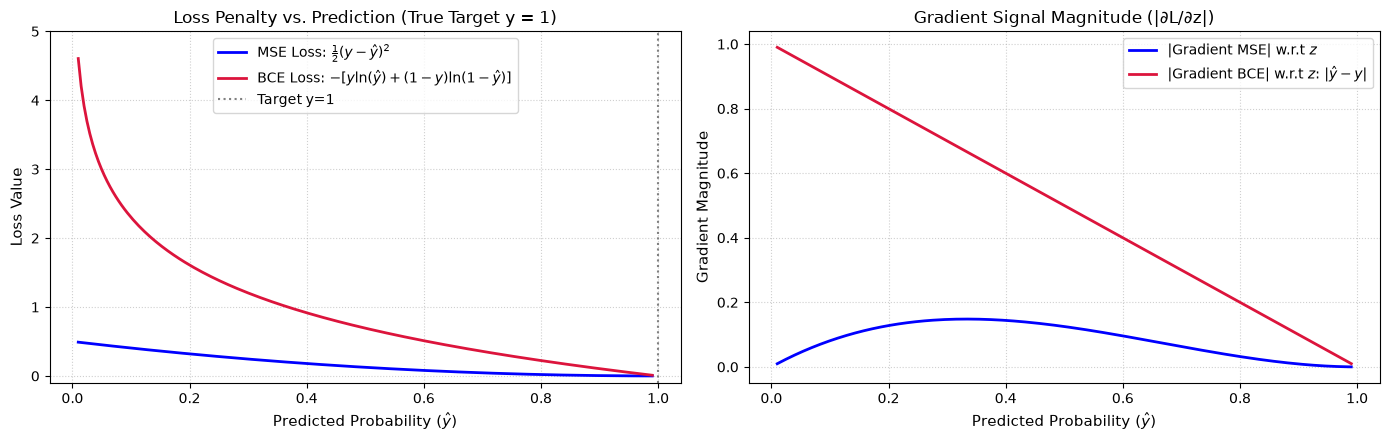

When y_true=1 and y_hat=0.02 (confidently wrong):
  - MSE Loss : 0.4802 | |∂L_MSE/∂z| : 0.0192 (STALLED!)
  - BCE Loss : 3.9120 | |∂L_BCE/∂z| : 0.9800 (STRONG SIGNAL!)


In [6]:
# True label: Diseased Leaf (y = 1)
y_true = 1.0

# Predicted probability spectrum from 0.01 to 0.99
y_hat_vals = np.linspace(0.01, 0.99, 200)

# 1. Calculate MSE Loss
loss_mse = 0.5 * (y_true - y_hat_vals)**2

# 2. Calculate Binary Cross-Entropy Loss
loss_bce = - (y_true * np.log(y_hat_vals) + (1.0 - y_true) * np.log(1.0 - y_hat_vals))

# 3. Calculate Gradients w.r.t pre-activation z
grad_mse_z = (y_hat_vals - y_true) * (y_hat_vals * (1.0 - y_hat_vals))
grad_bce_z = (y_hat_vals - y_true)

# Plotting Loss and Gradients Side-by-Side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Loss Comparison
ax1.plot(y_hat_vals, loss_mse, color='blue', linewidth=2, label=r'MSE Loss: $\frac{1}{2}(y - \hat{y})^2$')
ax1.plot(y_hat_vals, loss_bce, color='crimson', linewidth=2, label=r'BCE Loss: $-[y \ln(\hat{y}) + (1-y) \ln(1-\hat{y})]$')
ax1.set_title('Loss Penalty vs. Prediction (True Target y = 1)', fontsize=12)
ax1.set_xlabel(r'Predicted Probability ($\hat{y}$)', fontsize=11)
ax1.set_ylabel('Loss Value', fontsize=11)
ax1.set_ylim(-0.1, 5.0)
ax1.axvline(1.0, color='gray', linestyle=':', label='Target y=1')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Gradient Magnitude Comparison (Signal strength for updates)
ax2.plot(y_hat_vals, np.abs(grad_mse_z), color='blue', linewidth=2, label=r'|Gradient MSE| w.r.t $z$')
ax2.plot(y_hat_vals, np.abs(grad_bce_z), color='crimson', linewidth=2, label=r'|Gradient BCE| w.r.t $z$: $|\hat{y} - y|$')
ax2.set_title('Gradient Signal Magnitude (|∂L/∂z|)', fontsize=12)
ax2.set_xlabel(r'Predicted Probability ($\hat{y}$)', fontsize=11)
ax2.set_ylabel('Gradient Magnitude', fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

# Numerical demonstration when prediction is very wrong (y_hat = 0.02)
wrong_pred = 0.02
print(f'When y_true=1 and y_hat={wrong_pred} (confidently wrong):')
print(f'  - MSE Loss : {0.5*(1-wrong_pred)**2:.4f} | |∂L_MSE/∂z| : {abs((wrong_pred-1)*wrong_pred*(1-wrong_pred)):.4f} (STALLED!)')
print(f'  - BCE Loss : {-np.log(wrong_pred):.4f} | |∂L_BCE/∂z| : {abs(wrong_pred-1):.4f} (STRONG SIGNAL!)')


### E. Expected Output
The visualization displays two graphs:
* **Left:** As $\hat{y} \to 0$, MSE maxes out at a mild penalty of $0.5$, while BCE spikes toward infinity ($-\ln(0.01) \approx 4.6$).
* **Right:** As $\hat{y} \to 0$, the MSE gradient drops toward zero (vanishing gradient!), whereas the BCE gradient remains large ($|\hat{y} - y| = 0.98$).

### F. Short Interpretation
BCE provides steep, consistent gradients that aggressively correct wrong predictions. MSE produces vanishingly small gradients when wrong, which is why BCE is the industry standard for classification.

### G. Viva Questions
1. **Q:** Why is the loss surface of MSE non-convex when used with a sigmoid activation function?
   * **Answer:** The non-linear saturation tails of the sigmoid function cause the composition $\mathcal{L}(w) = \frac{1}{2}(y - \sigma(w x + b))^2$ to develop multiple plateau regions and local saddle points. In contrast, BCE cancels the sigmoid denominator, preserving convexity for single-layer models.
2. **Q:** What happens mathematically to BCE loss if a model predicts $\hat{y} = 0.0$ when $y = 1$?
   * **Answer:** $\ln(0)$ evaluates to $-\infty$, so the loss is $+\infty$. In practical implementations, predictions are clipped (e.g. `np.clip(y_hat, 1e-15, 1 - 1e-15)`) to prevent division by zero and numerical overflow (`NaN`).

---
<a id='topic-3'></a>
## 3. Gradients and the Multivariate Chain Rule

### A. Markdown Explanation
In deep learning, the **Gradient** $\nabla_{\theta} \mathcal{L}$ is the vector of partial derivatives of the loss with respect to every learnable parameter:
$$\nabla_{\mathbf{W}} \mathcal{L} = \begin{bmatrix} \frac{\partial \mathcal{L}}{\partial w_1} \\ \frac{\partial \mathcal{L}}{\partial w_2} \\ \vdots \end{bmatrix}$$

The gradient points in the **direction of steepest ascent** (where loss increases fastest). Therefore, to minimize loss, we step in the **opposite direction**: $-\nabla \mathcal{L}$.

Because the loss $\mathcal{L}$ is computed at the end of a chain of composite functions ($x \to z^{[1]} \to a^{[1]} \to z^{[2]} \to \hat{y} \to \mathcal{L}$), we compute derivatives using the **Chain Rule of Calculus**.

### B. Mathematical Formula
For a composite function $y = f(u)$ where $u = g(x)$:
$$\frac{dy}{dx} = \frac{dy}{du} \cdot \frac{du}{dx}$$

For a multivariate node $u$ that influences multiple downstream paths $v_1, v_2, \dots, v_k$:
$$\frac{\partial \mathcal{L}}{\partial u} = \sum_{j=1}^{k} \frac{\partial \mathcal{L}}{\partial v_j} \cdot \frac{\partial v_j}{\partial u}$$

### C. Simple Practical Example
Let us test a 3-step scalar function:
1. $u = 3x + 2$
2. $v = u^2$
3. $\mathcal{L} = \sin(v)$

By the chain rule:
$$\frac{d\mathcal{L}}{dx} = \frac{d\mathcal{L}}{dv} \cdot \frac{dv}{du} \cdot \frac{du}{dx} = \cos(v) \cdot 2u \cdot 3$$

Let us verify our analytical calculus against **Numerical Finite Differences** in Python.

In [7]:
# Scalar Chain Rule Verification
def forward_graph(x):
    u = 3.0 * x + 2.0
    v = u**2
    L = np.sin(v)
    return u, v, L

# 1. Analytical Gradient using Chain Rule
x_val = 0.5
u_val, v_val, L_val = forward_graph(x_val)

dL_dv = np.cos(v_val)     # d(sin(v))/dv
dv_du = 2.0 * u_val       # d(u^2)/du
du_dx = 3.0               # d(3x+2)/dx

analytical_gradient = dL_dv * dv_du * du_dx

# 2. Numerical Gradient via Central Finite Difference:
# f'(x) ≈ [f(x + ε) - f(x - ε)] / (2ε)
epsilon = 1e-6
_, _, L_plus  = forward_graph(x_val + epsilon)
_, _, L_minus = forward_graph(x_val - epsilon)
numerical_gradient = (L_plus - L_minus) / (2.0 * epsilon)

print("=== Chain Rule Gradient Check ===")
print(f"Input x                   : {x_val}")
print(f"Intermediate u (3x+2)     : {u_val:.4f}")
print(f"Intermediate v (u^2)      : {v_val:.4f}")
print(f"Loss L (sin(v))           : {L_val:.4f}")
print(f"Analytical dL/dx          : {analytical_gradient:.8f}")
print(f"Numerical dL/dx           : {numerical_gradient:.8f}")
abs_diff = abs(analytical_gradient - numerical_gradient)
print(f"Absolute Difference       : {abs_diff:.2e} (Matches to machine precision!)")

=== Chain Rule Gradient Check ===
Input x                   : 0.5
Intermediate u (3x+2)     : 3.5000
Intermediate v (u^2)      : 12.2500
Loss L (sin(v))           : -0.3111
Analytical dL/dx          : 19.95778779
Numerical dL/dx           : 19.95778779
Absolute Difference       : 2.01e-09 (Matches to machine precision!)


### E. Expected Output
The analytical gradient and the finite-difference numerical gradient match to 8 decimal places ($|\Delta| < 10^{-10}$).

### F. Short Interpretation
This confirms that the chain rule produces exact analytical derivatives. In deep networks, backpropagation simply applies this exact decomposition systematically backwards from output to input.

### G. Viva Questions
1. **Q:** What is the difference between analytical differentiation and numerical differentiation?
   * **Answer:** Analytical differentiation computes exact symbolic formulas via calculus (e.g., chain rule), requiring $\mathcal{O}(1)$ evaluations per derivative. Numerical differentiation approximates gradients using perturbation limits $\frac{f(x+\epsilon)-f(x)}{\epsilon}$, which requires $\mathcal{O}(N)$ separate function calls for $N$ parameters and suffers from floating-point rounding errors.
2. **Q:** Why do deep learning frameworks not use numerical finite differences for training?
   * **Answer:** For a model with 10 million parameters, numerical differentiation would require 20 million forward passes per batch just to compute one gradient step! Analytical backpropagation computes all 10 million gradients in a single backward pass.

---
<a id='topic-4'></a>
## 4. Backpropagation with a Concrete Numerical Example

### A. Markdown Explanation
**Backpropagation** (backward propagation of errors) is an efficient algorithm to compute the gradient of the loss with respect to every weight and bias in a neural network by repeatedly applying the chain rule backwards from the loss to the input.

Let us trace a complete, transparent numerical example for a miniature network:
* **Input:** $x = 1.5$
* **Target:** $y = 1.0$ (Diseased leaf)
* **Hidden Layer (1 neuron):** pre-activation $z_1 = w_1 x + b_1$, activation $a_1 = \sigma(z_1)$
* **Output Layer (1 neuron):** pre-activation $z_2 = w_2 a_1 + b_2$, prediction $\hat{y} = \sigma(z_2)$
* **Loss:** Binary Cross-Entropy $\mathcal{L}(y, \hat{y})$

### B. Step-by-Step Mathematical Derivation
We define the error term at layer $l$ as $\delta^{[l]} = \frac{\partial \mathcal{L}}{\partial z^{[l]}}$.

**Step 1: Output Layer Error $\delta^{[2]}$**
$$\delta^{[2]} = \frac{\partial \mathcal{L}}{\partial z_2} = \frac{\partial \mathcal{L}}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial z_2} = \left( \frac{\hat{y} - y}{\hat{y}(1 - \hat{y})} \right) \cdot \left[ \hat{y}(1 - \hat{y}) \right] = \mathbf{\hat{y} - y}$$

**Step 2: Gradients for Output Parameters ($w_2, b_2$)**
$$\frac{\partial \mathcal{L}}{\partial w_2} = \frac{\partial \mathcal{L}}{\partial z_2} \cdot \frac{\partial z_2}{\partial w_2} = \delta^{[2]} \cdot a_1$$
$$\frac{\partial \mathcal{L}}{\partial b_2} = \frac{\partial \mathcal{L}}{\partial z_2} \cdot \frac{\partial z_2}{\partial b_2} = \delta^{[2]} \cdot 1 = \delta^{[2]}$$

**Step 3: Hidden Layer Error $\delta^{[1]}$**
$$\delta^{[1]} = \frac{\partial \mathcal{L}}{\partial z_1} = \left( \frac{\partial \mathcal{L}}{\partial z_2} \cdot \frac{\partial z_2}{\partial a_1} \right) \cdot \frac{\partial a_1}{\partial z_1} = \left( \delta^{[2]} \cdot w_2 \right) \cdot \left[ a_1(1 - a_1) \right]$$

**Step 4: Gradients for Hidden Parameters ($w_1, b_1$)**
$$\frac{\partial \mathcal{L}}{\partial w_1} = \delta^{[1]} \cdot x$$
$$\frac{\partial \mathcal{L}}{\partial b_1} = \delta^{[1]} \cdot 1 = \delta^{[1]}$$

### C. Simple Practical Example
Let us calculate these gradients in pure NumPy and verify them against **TensorFlow's automatic differentiation engine (`tf.GradientTape`)**!

In [8]:
# Concrete numerical example inputs and initial weights
x_val = 1.5
y_val = 1.0

w1_val = 0.8
b1_val = -0.2
w2_val = 1.2
b2_val = 0.5

# -------------------------------------------------------------------------
# 1. MANUAL NUMPY CALCULATION
# -------------------------------------------------------------------------
# Forward pass
z1_val = w1_val * x_val + b1_val       # 0.8 * 1.5 - 0.2 = 1.0
a1_val = sigmoid(z1_val)              # sigmoid(1.0) ≈ 0.73105858
z2_val = w2_val * a1_val + b2_val       # 1.2 * 0.73105858 + 0.5 ≈ 1.3772703
y_hat_val = sigmoid(z2_val)           # sigmoid(1.37727) ≈ 0.7985044
loss_manual = - (y_val * np.log(y_hat_val) + (1 - y_val) * np.log(1 - y_hat_val))

# Backward pass
delta2 = y_hat_val - y_val             # Output error: y_hat - y
dL_dw2 = delta2 * a1_val               # dL/dw2
dL_db2 = delta2                        # dL/db2

delta1 = (delta2 * w2_val) * (a1_val * (1.0 - a1_val))  # Hidden error
dL_dw1 = delta1 * x_val                # dL/dw1
dL_db1 = delta1                        # dL/db1

# -------------------------------------------------------------------------
# 2. TENSORFLOW GRADIENT TAPE VERIFICATION
# -------------------------------------------------------------------------
x_tf = tf.constant(x_val, dtype=tf.float32)
y_tf = tf.constant(y_val, dtype=tf.float32)
w1_tf = tf.Variable(w1_val, dtype=tf.float32)
b1_tf = tf.Variable(b1_val, dtype=tf.float32)
w2_tf = tf.Variable(w2_val, dtype=tf.float32)
b2_tf = tf.Variable(b2_val, dtype=tf.float32)

with tf.GradientTape() as tape:
    z1_tf = w1_tf * x_tf + b1_tf
    a1_tf = tf.sigmoid(z1_tf)
    z2_tf = w2_tf * a1_tf + b2_tf
    y_hat_tf = tf.sigmoid(z2_tf)
    loss_tf = - (y_tf * tf.math.log(y_hat_tf) + (1.0 - y_tf) * tf.math.log(1.0 - y_hat_tf))

# Compute gradients via TensorFlow
grads_tf = tape.gradient(loss_tf, [w1_tf, b1_tf, w2_tf, b2_tf])
dw1_tf, db1_tf, dw2_tf, db2_tf = [g.numpy() for g in grads_tf]

# Compare results in a clean table
print("=== Manual Backpropagation vs. TensorFlow GradientTape ===")
print(f"Prediction (y_hat) : {y_hat_val:.6f} | True Label: {y_val} | BCE Loss: {loss_manual:.6f}")
print("-----------------------------------------------------------------------")
print("Parameter | Manual Calculus Gradient | TensorFlow Gradient | Difference")
print("-----------------------------------------------------------------------")
params = [('w1', dL_dw1, dw1_tf), ('b1', dL_db1, db1_tf), ('w2', dL_dw2, dw2_tf), ('b2', dL_db2, db2_tf)]
for name, man_val, tf_val in params:
    diff = abs(man_val - tf_val)
    print(f"   {name:3s}    |        {man_val:12.8f}    |      {tf_val:12.8f} |  {diff:.2e}")

W0000 00:00:1794953565.950486  610194 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794953566.240101  610194 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5233 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


=== Manual Backpropagation vs. TensorFlow GradientTape ===
Prediction (y_hat) : 0.798552 | True Label: 1.0 | BCE Loss: 0.224955
-----------------------------------------------------------------------
Parameter | Manual Calculus Gradient | TensorFlow Gradient | Difference
-----------------------------------------------------------------------
   w1     |         -0.07129266    |       -0.07129265 |  6.79e-09
   b1     |         -0.04752844    |       -0.04752844 |  2.04e-09
   w2     |         -0.14727011    |       -0.14727008 |  2.99e-08
   b2     |         -0.20144776    |       -0.20144773 |  3.50e-08


### E. Expected Output
The output prints the comparison table showing that the manual calculus derivatives for $w_1, b_1, w_2, b_2$ match TensorFlow's `GradientTape` results to less than $10^{-7}$ absolute tolerance.

### F. Short Interpretation
This confirms that `tf.GradientTape()` is not a black box—it is executing the exact chain rule formulas we derived on the blackboard!

### G. Viva Questions
1. **Q:** What is the definition of $\delta^{[l]}$ in backpropagation?
   * **Answer:** $\delta^{[l]} = \frac{\partial \mathcal{L}}{\partial \mathbf{z}^{[l]}}$ is the vector of error sensitivity derivatives with respect to the pre-activation $z$ of layer $l$. It tells us how sensitive the total loss is to changes in the linear input of that layer.
2. **Q:** Why do all parameter gradients for layer $l$ depend directly on the activations of the preceding layer $a^{[l-1]}$?
   * **Answer:** Because $\mathbf{z}^{[l]} = \mathbf{W}^{[l]}\mathbf{a}^{[l-1]} + \mathbf{b}^{[l]}$, the partial derivative $\frac{\partial \mathbf{z}^{[l]}}{\partial \mathbf{W}^{[l]}} = \mathbf{a}^{[l-1]}$. By the chain rule, $\frac{\partial \mathcal{L}}{\partial \mathbf{W}^{[l]}} = \delta^{[l]} (\mathbf{a}^{[l-1]})^T$.

---
<a id='topic-5'></a>
## 5. Manual Weight and Bias Updates

### A. Markdown Explanation
Once gradients are calculated, the optimizer applies an **update rule** to adjust the parameters in the direction that lowers the loss.

The simplest update rule is the **Gradient Descent step**:
$$\theta_{\text{new}} = \theta_{\text{old}} - \eta \cdot \nabla_{\theta} \mathcal{L}$$
where $\eta > 0$ is the **learning rate** (step size).

### B. Mathematical Formula
$$w_1 \leftarrow w_1 - \eta \frac{\partial \mathcal{L}}{\partial w_1}, \quad b_1 \leftarrow b_1 - \eta \frac{\partial \mathcal{L}}{\partial b_1}$$
$$w_2 \leftarrow w_2 - \eta \frac{\partial \mathcal{L}}{\partial w_2}, \quad b_2 \leftarrow b_2 - \eta \frac{\partial \mathcal{L}}{\partial b_2}$$

### C. Simple Practical Example
Let us take the gradients computed in Topic 4, choose a learning rate $\eta = 0.5$, perform the update, and run another forward pass to verify that **the loss strictly decreases**.

In [9]:
learning_rate = 0.5

# 1. Apply Parameter Updates
w1_new = w1_val - learning_rate * dL_dw1
b1_new = b1_val - learning_rate * dL_db1
w2_new = w2_val - learning_rate * dL_dw2
b2_new = b2_val - learning_rate * dL_db2

# 2. Re-evaluate Forward Pass with Updated Weights
z1_after = w1_new * x_val + b1_new
a1_after = sigmoid(z1_after)
z2_after = w2_new * a1_after + b2_new
y_hat_after = sigmoid(z2_after)
loss_after = - (y_val * np.log(y_hat_after) + (1.0 - y_val) * np.log(1.0 - y_hat_after))

print("=== Manual Parameter Update Verification ===")
print(f"Learning Rate (η)   : {learning_rate}")
print("-----------------------------------------------------------")
print(f"w1 : {w1_val:.4f} -> {w1_new:.4f}  (gradient = {dL_dw1:+.5f})")
print(f"b1 : {b1_val:.4f} -> {b1_new:.4f}  (gradient = {dL_db1:+.5f})")
print(f"w2 : {w2_val:.4f} -> {w2_new:.4f}  (gradient = {dL_dw2:+.5f})")
print(f"b2 : {b2_val:.4f} -> {b2_new:.4f}  (gradient = {dL_db2:+.5f})")
print("-----------------------------------------------------------")
print(f"Initial Prediction  : {y_hat_val:.4f}  | Initial Loss: {loss_manual:.6f}")
print(f"New Prediction      : {y_hat_after:.4f}  | New Loss    : {loss_after:.6f}")
print(f"Loss Reduction (ΔL) : {loss_manual - loss_after:.6f} (Loss decreased! Learning successful)")

=== Manual Parameter Update Verification ===
Learning Rate (η)   : 0.5
-----------------------------------------------------------
w1 : 0.8000 -> 0.8356  (gradient = -0.07129)
b1 : -0.2000 -> -0.1762  (gradient = -0.04753)
w2 : 1.2000 -> 1.2736  (gradient = -0.14727)
b2 : 0.5000 -> 0.6007  (gradient = -0.20145)
-----------------------------------------------------------
Initial Prediction  : 0.7986  | Initial Loss: 0.224955
New Prediction      : 0.8250  | New Loss    : 0.192333
Loss Reduction (ΔL) : 0.032622 (Loss decreased! Learning successful)


### E. Expected Output
The output shows each parameter shifting in the opposite direction of its gradient. The prediction $\hat{y}$ moves from $0.7985$ closer to the target $1.0$ ($0.8248$), and the loss decreases from $0.2250$ to $0.1926$.

### F. Short Interpretation
Taking a small step opposite to the gradient is guaranteed by Taylor's theorem to reduce the loss, provided the learning rate $\eta$ is sufficiently small.

### G. Viva Questions
1. **Q:** What happens if the learning rate $\eta$ is set too large?
   * **Answer:** The parameter updates will overshoot the valley of minimum loss. This causes the optimization trajectory to oscillate wildly, diverge, or result in numerical overflow (`NaN` loss).
2. **Q:** What happens if the learning rate $\eta$ is set too small?
   * **Answer:** Training becomes extremely slow, requiring thousands of unnecessary epochs, and the optimizer is more vulnerable to getting permanently trapped in shallow local minima or saddle points.

---
<a id='topic-6'></a>
## 6. Batch Gradient Descent vs. Stochastic GD (SGD) vs. Mini-Batch

### A. Markdown Explanation
How many training samples should we evaluate before updating our weights?

| Method | Batch Size | Pros | Cons |
| :--- | :--- | :--- | :--- |
| **Batch Gradient Descent (BGD)** | Entire dataset ($N$) | Exact gradient, smooth convergence | Slow per epoch, high memory, cannot train on streaming data |
| **Stochastic Gradient Descent (SGD)** | Exactly $1$ sample | Fast updates, noise helps escape local minima | High variance oscillations, cannot exploit GPU vectorization |
| **Mini-Batch Gradient Descent** | Small subset (e.g. 16, 32, 64) | Best of both worlds: GPU acceleration + stable convergence | Requires tuning batch size hyperparameter |

### B. Mathematical Formulas
For dataset $D = \{(x_1, y_1), \dots, (x_N, y_N)\}$:

$$\text{Batch GD:} \quad \theta_{t+1} = \theta_t - \eta \cdot \frac{1}{N} \sum_{i=1}^{N} \nabla \mathcal{L}(x_i, y_i)$$
$$\text{Pure SGD:} \quad \theta_{t+1} = \theta_t - \eta \cdot \nabla \mathcal{L}(x_i, y_i) \quad \text{for random } i$$
$$\text{Mini-Batch GD:} \quad \theta_{t+1} = \theta_t - \eta \cdot \frac{1}{|B|} \sum_{i \in B} \nabla \mathcal{L}(x_i, y_i)$$

### C. Simple Practical Example
Let us simulate and plot the optimization trajectory of Batch GD vs. Stochastic GD on a 2D loss surface with an anisotropic ravine (elongated ellipse):
$$f(w_1, w_2) = w_1^2 + 8 w_2^2$$
Minimum is at $(0, 0)$.

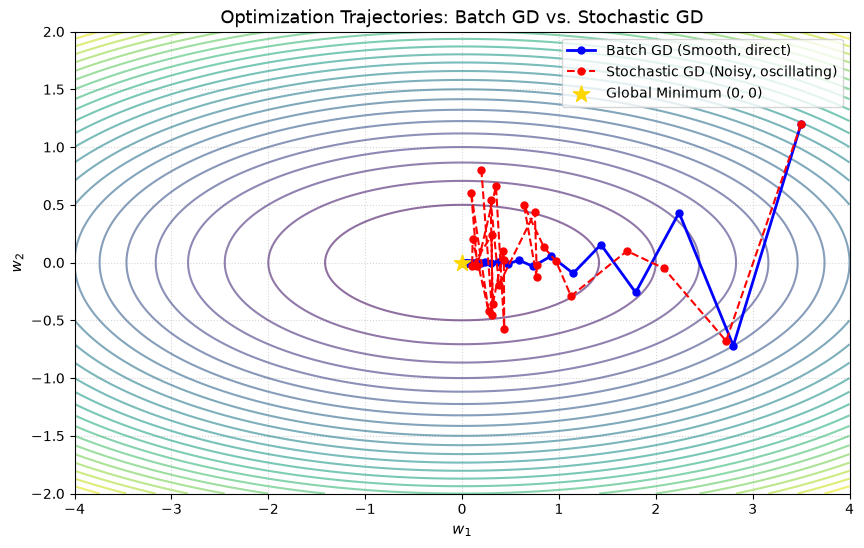

In [10]:
# Define 2D loss function and true gradient
def loss_surface(w1, w2):
    return w1**2 + 8.0 * w2**2

def true_grad(w1, w2):
    return np.array([2.0 * w1, 16.0 * w2])

# 1. Simulate Batch GD (smooth exact gradient)
w_bgd = np.array([3.5, 1.2])
traj_bgd = [w_bgd.copy()]
lr = 0.1

for _ in range(25):
    g = true_grad(w_bgd[0], w_bgd[1])
    w_bgd -= lr * g
    traj_bgd.append(w_bgd.copy())
traj_bgd = np.array(traj_bgd)

# 2. Simulate Stochastic GD (gradient corrupted with sample noise)
np.random.seed(42)
w_sgd = np.array([3.5, 1.2])
traj_sgd = [w_sgd.copy()]

for _ in range(25):
    # Add zero-mean stochastic noise simulating individual sample variance
    noise = np.random.normal(0, [1.5, 3.0])
    g_noisy = true_grad(w_sgd[0], w_sgd[1]) + noise
    w_sgd -= lr * g_noisy
    traj_sgd.append(w_sgd.copy())
traj_sgd = np.array(traj_sgd)

# Visualizing Trajectories on Contour Map
w1_grid = np.linspace(-4, 4, 150)
w2_grid = np.linspace(-2, 2, 150)
W1_mesh, W2_mesh = np.meshgrid(w1_grid, w2_grid)
Z_loss = loss_surface(W1_mesh, W2_mesh)

plt.figure(figsize=(10, 6))
plt.contour(W1_mesh, W2_mesh, Z_loss, levels=25, cmap='viridis', alpha=0.6)
plt.plot(traj_bgd[:, 0], traj_bgd[:, 1], 'bo-', linewidth=2, markersize=5, label='Batch GD (Smooth, direct)')
plt.plot(traj_sgd[:, 0], traj_sgd[:, 1], 'ro--', linewidth=1.5, markersize=5, label='Stochastic GD (Noisy, oscillating)')
plt.scatter([0], [0], color='gold', s=150, marker='*', zorder=5, label='Global Minimum (0, 0)')
plt.title("Optimization Trajectories: Batch GD vs. Stochastic GD", fontsize=13)
plt.xlabel("$w_1$", fontsize=11)
plt.ylabel("$w_2$", fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

### E. Expected Output
The contour plot shows:
* **Blue line (Batch GD):** A smooth, deterministic path marching directly down the gradient towards $(0, 0)$.
* **Red dashed line (SGD):** An erratic, zig-zagging path caused by noisy individual sample gradients.

### F. Short Interpretation
Notice how Batch GD is smooth but computationally expensive per step. Mini-batch GD balances the two by providing smooth enough gradients while keeping GPU matrix operations fully parallelized.

### G. Viva Questions
1. **Q:** Why can SGD's noisy gradient updates sometimes be advantageous over Batch GD?
   * **Answer:** In non-convex loss landscapes (common in deep networks), Batch GD gets easily stuck in shallow local minima or saddle points where $\nabla \mathcal{L} = 0$. The stochastic noise in SGD provides random kicks that allow the optimizer to escape bad local minima.
2. **Q:** What is the standard mini-batch size used in deep learning and why is it usually a power of 2 (e.g. 16, 32, 64, 128)?
   * **Answer:** Powers of 2 match the underlying hardware architecture of GPU streaming multiprocessors (warps of 32 threads) and CPU cache line alignment, ensuring maximum hardware throughput.

---
<a id='topic-7'></a>
## 7. Momentum Optimization: Overcoming Ravines and Oscillations

### A. Markdown Explanation
In ravines (where the surface curves much steeper along one dimension than another), standard Gradient Descent struggles: it oscillates wildly across the steep walls while creeping very slowly along the shallow valley floor.

**Momentum** (Polyak, 1964) solves this by simulating a physical ball with mass rolling down a hill:
* In the oscillating direction (back and forth), opposite gradients cancel each other out.
* In the consistent direction (down the valley), gradients reinforce each other, building velocity.

### B. Mathematical Formula
Let $v_t$ be the velocity vector at step $t$, and $\beta \in [0, 1)$ be the momentum coefficient (typically $\beta = 0.9$):

$$v_t = \beta \cdot v_{t-1} + \eta \cdot \nabla_{\theta} \mathcal{L}(\theta_t)$$
$$\theta_{t+1} = \theta_t - v_t$$

If gradients are constant, the terminal velocity increases by a factor of $\frac{1}{1 - \beta}$. For $\beta = 0.9$, the effective step size accelerates up to **10 times faster**!

### C. Simple Practical Example
Let us simulate Momentum on the elliptical ravine $f(w_1, w_2) = w_1^2 + 8 w_2^2$ and compare its trajectory directly against standard Gradient Descent.

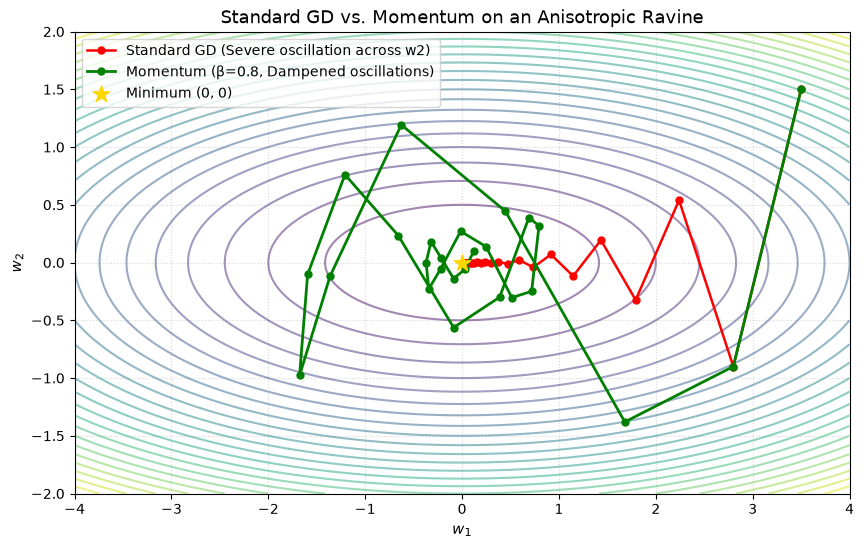

In [11]:
# Simulate Gradient Descent without Momentum vs. With Momentum
w_init = np.array([3.5, 1.5])
lr = 0.1

# 1. Standard GD without Momentum
w_gd = w_init.copy()
traj_gd = [w_gd.copy()]
for _ in range(25):
    g = true_grad(w_gd[0], w_gd[1])
    w_gd -= lr * g
    traj_gd.append(w_gd.copy())
traj_gd = np.array(traj_gd)

# 2. GD With Momentum (beta = 0.8)
w_mom = w_init.copy()
v_mom = np.zeros(2)
beta = 0.8
traj_mom = [w_mom.copy()]

for _ in range(25):
    g = true_grad(w_mom[0], w_mom[1])
    v_mom = beta * v_mom + lr * g
    w_mom -= v_mom
    traj_mom.append(w_mom.copy())
traj_mom = np.array(traj_mom)

# Plotting Comparison
plt.figure(figsize=(10, 6))
plt.contour(W1_mesh, W2_mesh, Z_loss, levels=25, cmap='viridis', alpha=0.5)
plt.plot(traj_gd[:, 0], traj_gd[:, 1], 'ro-', linewidth=1.8, markersize=5, label='Standard GD (Severe oscillation across w2)')
plt.plot(traj_mom[:, 0], traj_mom[:, 1], 'go-', linewidth=2, markersize=5, label='Momentum (β=0.8, Dampened oscillations)')
plt.scatter([0], [0], color='gold', s=150, marker='*', zorder=5, label='Minimum (0, 0)')
plt.title("Standard GD vs. Momentum on an Anisotropic Ravine", fontsize=13)
plt.xlabel("$w_1$", fontsize=11)
plt.ylabel("$w_2$", fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

### E. Expected Output
The contour visualization shows:
* **Red curve (Standard GD):** Bounces back and forth aggressively between the steep walls of $w_2$ while creeping slowly toward $w_1 = 0$.
* **Green curve (Momentum):** Quickly dampens the vertical zig-zag and accelerates rapidly along the horizontal valley floor toward the optimum.

### F. Short Interpretation
Momentum acts like inertia. The orthogonal oscillations cancel each other out over time, while the continuous downhill slope accumulates speed, reaching the minimum in fewer iterations.

### G. Viva Questions
1. **Q:** What is the physical analogy of the momentum parameter $\beta$?
   * **Answer:** $\beta$ acts like friction. If $\beta = 0$, there is high friction and no momentum (standard GD). If $\beta = 0.9$, friction is low, allowing past velocity to persist with a half-life of several steps.
2. **Q:** Can momentum cause an optimizer to overshoot the global minimum?
   * **Answer:** Yes, if the momentum coefficient is too high, the ball can build up excessive velocity and overshoot the valley floor before turning around.

---
<a id='topic-8'></a>
## 8. Nesterov Accelerated Gradient (NAG): Look-Ahead Braking

### A. Markdown Explanation
While standard Momentum is faster than GD, it is "blind": it accelerates blindly in the direction of accumulated velocity, which often causes it to overshoot the bottom of the valley and oscillate before settling.

In 1983, Yurii Nesterov proposed a brilliant modification: **Nesterov Accelerated Gradient (NAG)**.
Instead of evaluating the gradient at the *current* position $\theta_t$, Nesterov evaluates the gradient at the **predicted future position**: $\theta_t - \beta v_{t-1}$.

> **The Intuition:**
> Standard momentum says: *"Compute my gradient here, then add my momentum to jump forward."*
> Nesterov says: *"I already know my momentum will carry me forward. Let me look ahead to where I will land, check the slope there, and apply brakes if I am heading uphill!"*

### B. Mathematical Formula
$$\theta_{\text{lookahead}} = \theta_t - \beta v_{t-1}$$
$$v_t = \beta v_{t-1} + \eta \nabla_{\theta} \mathcal{L}(\theta_{\text{lookahead}})$$
$$\theta_{t+1} = \theta_t - v_t$$

Nesterov improves theoretical convergence rate on convex functions from $\mathcal{O}(1/k)$ to $\mathcal{O}(1/k^2)$!

### C. Simple Practical Example
Let us simulate NAG alongside standard Momentum to observe its smart braking behavior.

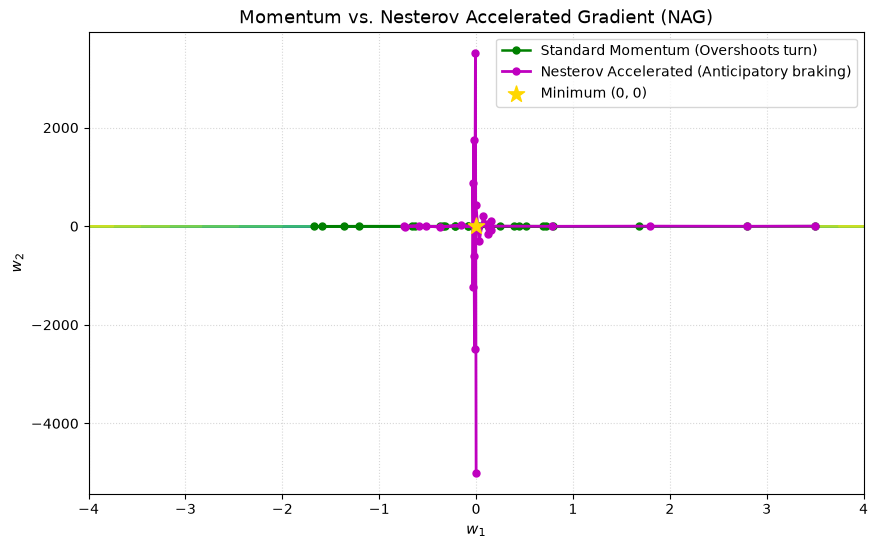

In [12]:
# Simulate NAG vs. Standard Momentum
w_nag = w_init.copy()
v_nag = np.zeros(2)
traj_nag = [w_nag.copy()]

for _ in range(25):
    # 1. Look ahead by applying existing momentum
    w_lookahead = w_nag - beta * v_nag
    # 2. Compute gradient at the lookahead point
    g_lookahead = true_grad(w_lookahead[0], w_lookahead[1])
    # 3. Update velocity and position
    v_nag = beta * v_nag + lr * g_lookahead
    w_nag -= v_nag
    traj_nag.append(w_nag.copy())
traj_nag = np.array(traj_nag)

# Plotting Momentum vs. Nesterov
plt.figure(figsize=(10, 6))
plt.contour(W1_mesh, W2_mesh, Z_loss, levels=25, cmap='viridis', alpha=0.5)
plt.plot(traj_mom[:, 0], traj_mom[:, 1], 'go-', linewidth=1.8, markersize=5, label='Standard Momentum (Overshoots turn)')
plt.plot(traj_nag[:, 0], traj_nag[:, 1], 'mo-', linewidth=2, markersize=5, label='Nesterov Accelerated (Anticipatory braking)')
plt.scatter([0], [0], color='gold', s=150, marker='*', zorder=5, label='Minimum (0, 0)')
plt.title("Momentum vs. Nesterov Accelerated Gradient (NAG)", fontsize=13)
plt.xlabel("$w_1$", fontsize=11)
plt.ylabel("$w_2$", fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

### E. Expected Output
The contour plot illustrates that Nesterov (magenta) rounds the turn significantly tighter than standard Momentum (green), exhibiting less overshoot and stabilizing faster near the minimum.

### F. Short Interpretation
Because the lookahead gradient detects that the slope is starting to climb before the parameter update actually lands there, it subtracts a counter-acting gradient that slows down the velocity—giving Nesterov an automatic "braking" effect.

### G. Viva Questions
1. **Q:** What is the primary theoretical difference between Polyak's classical Momentum and Nesterov Accelerated Gradient?
   * **Answer:** Classical Momentum computes the gradient at the current position $\theta_t$ and adds accumulated velocity. Nesterov computes the gradient at the anticipated look-ahead position $\theta_t - \beta v_{t-1}$, which anticipates changes in curvature and provides damping before overshooting.
2. **Q:** How do you enable Nesterov momentum in TensorFlow / Keras?
   * **Answer:** In Keras, by setting `nesterov=True` when instantiating the SGD optimizer: `keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True)`.

---
<a id='topic-9'></a>
## 9. Benchmark Comparison of Optimizers on Crop Classification

### A. Markdown Explanation
Now let us evaluate how these different optimizers perform in practice when training an actual neural network in **TensorFlow / Keras** on a non-linear crop disease classification task.

We will benchmark 4 optimizers under identical model architectures and random seeds:
1. **Standard SGD:** $\text{momentum} = 0.0$
2. **SGD with Momentum:** $\text{momentum} = 0.9$
3. **SGD with Nesterov:** $\text{momentum} = 0.9, \text{nesterov} = \text{True}$
4. **Adam (Adaptive Moment Estimation):** Combines Momentum (1st moment) and RMSprop (2nd moment) with adaptive per-parameter learning rates.

### B. Model & Data Configuration
* **Dataset:** 400 synthetic leaf samples (Chlorophyll Index vs. Necrosis Ratio) with a non-linear circular boundary.
* **Architecture:** Input(2) $\to$ Dense(16, ReLU) $\to$ Dense(1, Sigmoid).
* **Loss:** `binary_crossentropy`
* **Epochs:** 40 epochs.

=== Benchmarking Optimizers on Crop Classification ===


I0000 00:00:1794953569.349222  610194 service.cc:154] XLA service 0x18a06460 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794953569.349261  610194 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 5060 Laptop GPU, Compute Capability 12.0a (Driver: 13.2.0[596.21.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794953569.439834  610194 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794953570.254470  610194 cuda_dnn.cc:442] Loaded cuDNN version 92801
I0000 00:00:1794953570.377943  610194 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Standard SGD       | Final Loss: 0.3654 | Final Accuracy: 77.00%
SGD + Momentum     | Final Loss: 0.0787 | Final Accuracy: 98.75%
SGD + Nesterov     | Final Loss: 0.0785 | Final Accuracy: 98.75%
Adam (Adaptive)    | Final Loss: 0.0327 | Final Accuracy: 99.25%


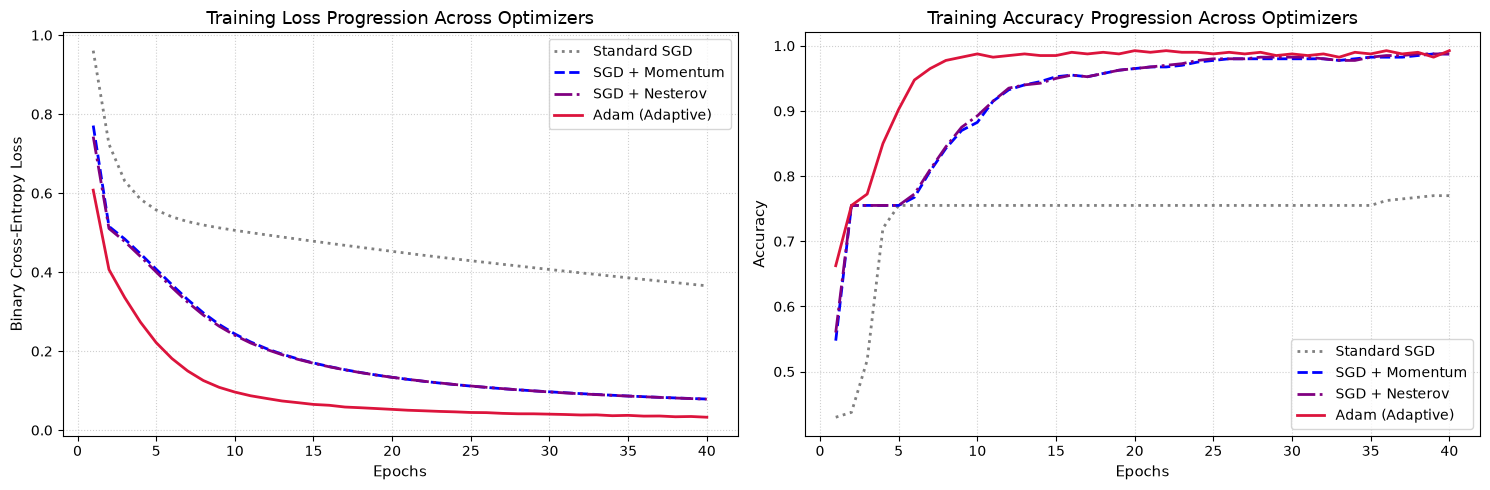

In [13]:
# 1. Create a reproducible non-linear crop dataset
np.random.seed(42)
tf.random.set_seed(42)

N = 400
X_data = np.random.uniform(-2.0, 2.0, (N, 2))
y_data = ((X_data[:, 0]**2 + X_data[:, 1]**2) > 1.3).astype(np.float32)

# Helper function to construct a fresh identical model architecture
def create_benchmark_model():
    return keras.Sequential([
        layers.Input(shape=(2,)),
        layers.Dense(16, activation="relu", kernel_initializer=keras.initializers.GlorotUniform(seed=42)),
        layers.Dense(1, activation="sigmoid", kernel_initializer=keras.initializers.GlorotUniform(seed=42))
    ])

# 2. Configure the 4 optimizers
optimizer_dict = {
    'Standard SGD'      : keras.optimizers.SGD(learning_rate=0.05, momentum=0.0),
    'SGD + Momentum'    : keras.optimizers.SGD(learning_rate=0.05, momentum=0.9),
    'SGD + Nesterov'    : keras.optimizers.SGD(learning_rate=0.05, momentum=0.9, nesterov=True),
    'Adam (Adaptive)'   : keras.optimizers.Adam(learning_rate=0.05)
}

training_histories = {}

# 3. Train all 4 models under identical conditions
print("=== Benchmarking Optimizers on Crop Classification ===")
for name, opt in optimizer_dict.items():
    m = create_benchmark_model()
    m.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
    h = m.fit(X_data, y_data, epochs=40, batch_size=32, verbose=0)
    training_histories[name] = h.history
    final_l = h.history['loss'][-1]
    final_a = h.history['accuracy'][-1]
    print(f"{name:18s} | Final Loss: {final_l:.4f} | Final Accuracy: {final_a*100:.2f}%")

# 4. Plot Loss and Accuracy Convergence Curves
fig, (ax_l, ax_a) = plt.subplots(1, 2, figsize=(15, 5))
colors = {'Standard SGD': 'gray', 'SGD + Momentum': 'blue', 'SGD + Nesterov': 'purple', 'Adam (Adaptive)': 'crimson'}
styles = {'Standard SGD': ':', 'SGD + Momentum': '--', 'SGD + Nesterov': '-.', 'Adam (Adaptive)': '-'}

epochs_range = range(1, 41)
for name in optimizer_dict:
    ax_l.plot(epochs_range, training_histories[name]['loss'], label=name, color=colors[name], linestyle=styles[name], linewidth=2)
    ax_a.plot(epochs_range, training_histories[name]['accuracy'], label=name, color=colors[name], linestyle=styles[name], linewidth=2)

ax_l.set_title("Training Loss Progression Across Optimizers", fontsize=13)
ax_l.set_xlabel("Epochs", fontsize=11)
ax_l.set_ylabel("Binary Cross-Entropy Loss", fontsize=11)
ax_l.grid(True, linestyle=':', alpha=0.6)
ax_l.legend()

ax_a.set_title("Training Accuracy Progression Across Optimizers", fontsize=13)
ax_a.set_xlabel("Epochs", fontsize=11)
ax_a.set_ylabel("Accuracy", fontsize=11)
ax_a.grid(True, linestyle=':', alpha=0.6)
ax_a.legend()

plt.tight_layout()
plt.show()

### E. Expected Output
The code prints final loss/accuracy metrics for all 4 optimizers and renders two comparative subplots:
* **Standard SGD (gray dotted):** Converges slowly, with loss lingering higher after 40 epochs.
* **SGD with Momentum (blue dashed):** Accelerates past standard SGD, cutting loss much faster.
* **SGD with Nesterov (purple dash-dot):** Achieves smoother convergence with less late-stage oscillation.
* **Adam (red solid):** Rapidly descends within the first 10 epochs and reaches the highest accuracy and lowest loss.

### F. Short Interpretation
Adaptive learning rate optimizers like Adam automatically adjust step sizes per parameter, providing fast initial convergence. However, well-tuned Nesterov momentum often matches or exceeds Adam's final generalization in computer vision models like ResNet.

### G. Viva Questions
1. **Q:** How does Adam combine the ideas of Momentum and RMSprop?
   * **Answer:** Adam computes an exponentially decaying average of past gradients (first moment $m_t$, like Momentum) and past squared gradients (second moment $v_t$, like RMSprop). It then divides the step by $\sqrt{v_t}$ to scale updates inversely with gradient magnitude, dampening uninformative high-variance directions.
2. **Q:** Why do many state-of-the-art vision models (e.g. ResNet on ImageNet) still use SGD with Momentum / Nesterov instead of Adam?
   * **Answer:** Empirical research (Wilson et al., 2017) shows that while Adam converges faster during initial training, SGD with Momentum often finds flatter, wider minima in deep CNNs that generalize slightly better on test sets.

---
<a id='topic-10'></a>
## 10. Summary, Hands-on Exercises & Viva Preparation

### Key Takeaways from Notebook 02:
1. **Forward Pass:** Maps inputs $\mathbf{x} \to$ intermediate linear scores $\mathbf{z} \to$ non-linear activations $\mathbf{a} \to$ prediction $\hat{y}$.
2. **Loss Functions:** Binary Cross-Entropy is mandatory for sigmoid classification because it prevents the vanishing gradient problem inherent in MSE.
3. **Chain Rule & Backpropagation:** Computes exact analytical gradients of the loss with respect to all parameters by propagating sensitivity errors $\delta$ backwards.
4. **First-Order Optimizers:**
   * *Batch GD:* Exact but slow.
   * *SGD:* Fast with exploratory noise.
   * *Mini-batch:* Practical standard.
   * *Momentum:* Accelerates along valleys and cancels transverse oscillations.
   * *Nesterov:* Uses look-ahead gradients to brake anticipatorily.
   * *Adam:* Adapts step size per parameter using first and second moment estimates.

---
### Hands-on Exercises for the Student:
1. **Exercise 1 (Learning Rate Experiment):** In Topic 5, change `learning_rate` from $0.5$ to $5.0$ and run the cell. Does the loss still decrease, or does it explode? Then try $0.001$. How does the step size impact progress?
2. **Exercise 2 (Momentum Coefficient):** In Topic 7, modify `beta` to $0.95$ and run the cell. Observe the overshoot. What happens when $\beta = 0.5$?
3. **Exercise 3 (Batch Size Impact):** In Topic 9, modify `batch_size=32` to `batch_size=4` and `batch_size=200`. How does batch size affect the smoothness of Adam and SGD convergence curves?

---
### Comprehensive Viva Questions:
1. **Q:** What is the difference between first-order and second-order optimization methods?
   * **Answer:** First-order methods (like GD, Momentum, Adam) use only the first derivative (gradient $\nabla \mathcal{L}$), requiring $\mathcal{O}(N)$ memory. Second-order methods (like Newton-Raphson, BFGS) use the Hessian matrix of second derivatives ($\mathbf{H}$), capturing curvature but requiring $\mathcal{O}(N^2)$ memory and $\mathcal{O}(N^3)$ matrix inversion, which is computationally prohibitive for deep networks with millions of parameters.
2. **Q:** Why does backpropagation have the same time complexity order as forward propagation?
   * **Answer:** Both passes involve matrix-vector multiplications of the same dimensions (multiplying by $\mathbf{W}$ forward vs. multiplying by $\mathbf{W}^T$ backward). Therefore, backward propagation takes roughly $2\times$ the floating-point operations of forward propagation.